!pip install -q pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost joblib

In [2]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib
import os

warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    ConfusionMatrixDisplay
)

from sklearn.impute import SimpleImputer

sns.set_style("whitegrid")

# Dataset information
print("Dataset Shape:", credit_frame.shape)
print("\nDataset Columns:")
print(credit_frame.columns.tolist())

print("\nDataset Information:")
credit_frame.info()

print("\nMissing Values:")
print(credit_frame.isnull().sum().sum())

print("\nDuplicate Records:")
print(credit_frame.duplicated().sum())

print("\nStatistical Summary:")
display(credit_frame.describe())

NameError: name 'credit_frame' is not defined

Target Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Missing Values:
Time      0
V16       0
Amount    0
V28       0
V27       0
V26       0
V25       0
V24       0
V23       0
V22       0
dtype: int64


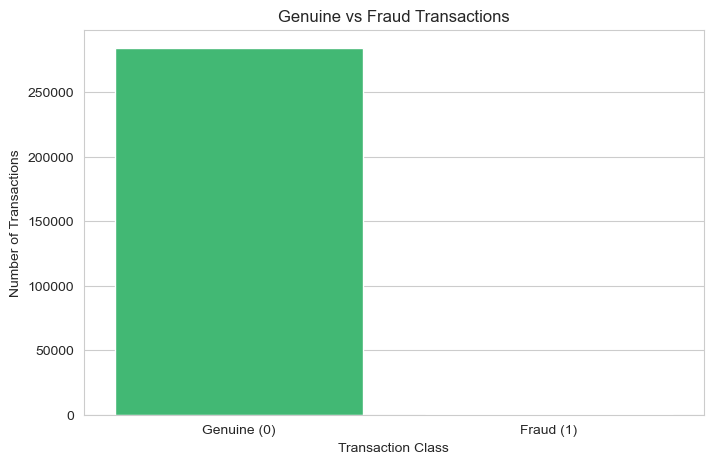


Class Percentage:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


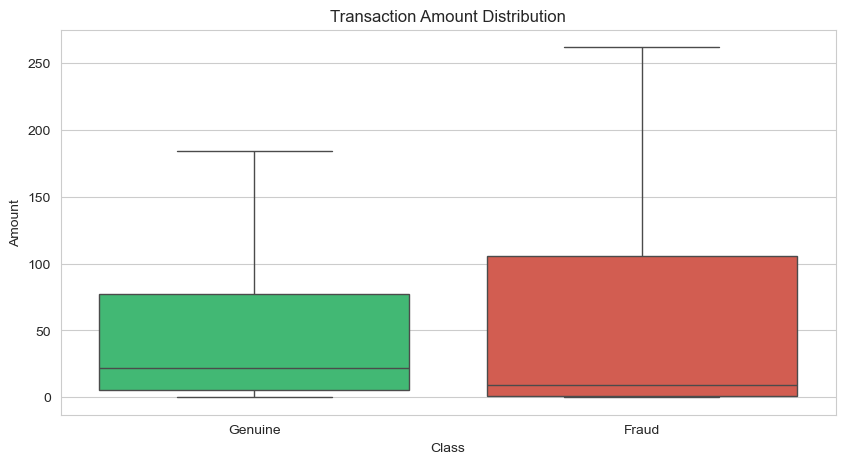

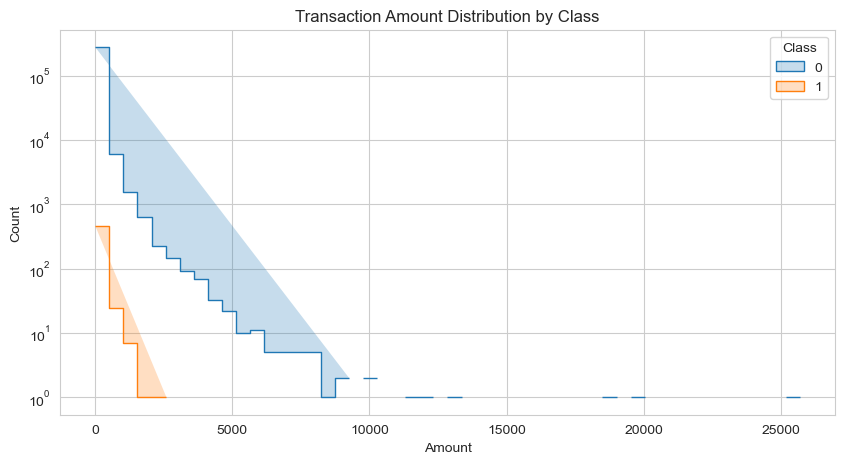

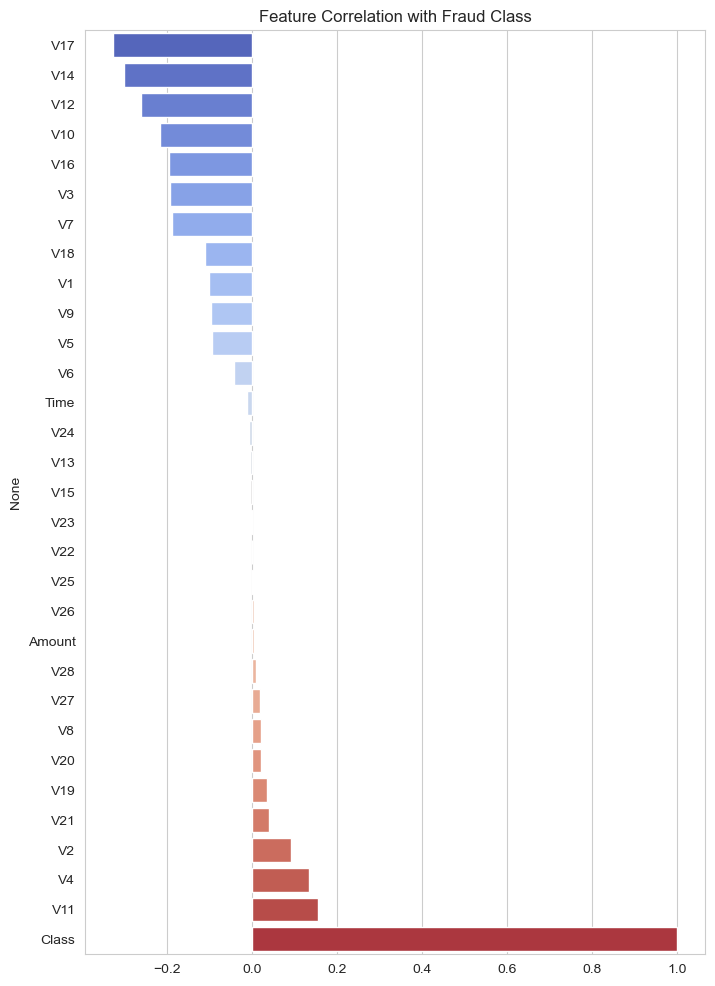

,count,mean,median,min,max
Class,,,,,
0,284315,88.291022,22.00,0.0,25691.16
1,492,122.211321,9.25,0.0,2125.87


In [ ]:
# EDA - EXPLOARTY DATA ANALYSIS

# Create working copy
df = credit_frame.copy()

# Check target column
if 'Class' not in df.columns:
    raise ValueError("Target column 'Class' not found!")

# Separate target and features
print("Target Distribution:")
print(df['Class'].value_counts())

# Missing values
print("\nMissing Values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

# Class distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Class',
    hue='Class',
    palette=['#2ecc71', '#e74c3c'],
    legend=False
)

plt.title("Genuine vs Fraud Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ['Genuine (0)', 'Fraud (1)'])
plt.show()

# Percentage distribution
class_percentage = df['Class'].value_counts(normalize=True) * 100

print("\nClass Percentage:")
print(class_percentage)

# Fraud and genuine amount analysis
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='Class',
    y='Amount',
    hue='Class',
    palette=['#2ecc71', '#e74c3c'],
    showfliers=False,
    legend=False
)

plt.title("Transaction Amount Distribution")
plt.xticks([0, 1], ['Genuine', 'Fraud'])
plt.show()

# Amount distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='Amount',
    hue='Class',
    bins=50,
    log_scale=(False, True),
    element='step'
)

plt.title("Transaction Amount Distribution by Class")
plt.show()

# Correlation with target
plt.figure(figsize=(8, 12))

target_corr = df.corr(numeric_only=True)['Class'].sort_values()

sns.barplot(
    x=target_corr.values,
    y=target_corr.index,
    hue=target_corr.index,
    palette='coolwarm',
    legend=False
)

plt.title("Feature Correlation with Fraud Class")
plt.show()

# Class statistics
display(
    df.groupby('Class')['Amount'].agg(
        ['count', 'mean', 'median', 'min', 'max']
    )
)

In [ ]:
# DATA PREPROCESSING AND TRAIN - TEST SPLIT

# Separate input and target
X = df.drop(columns=['Class'])
y = df['Class'].astype(int)

# Check target labels
print("Unique Target Values:", sorted(y.unique()))

# Validate dataset
if not set(y.unique()).issubset({0, 1}):
    raise ValueError("Class must contain only 0 and 1.")

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

print("\nFraud percentage in test data:")
print(round(y_test.mean() * 100, 4), "%")

Unique Target Values: [np.int64(0), np.int64(1)]
Training Data: (227845, 30)
Testing Data: (56962, 30)

Training Class Distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing Class Distribution:
Class
0    56864
1       98
Name: count, dtype: int64

Fraud percentage in test data:
0.172 %


In [ ]:
# CREATE TRAINING AND VALIDATION PIPLINE
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Sub-training shape:", X_subtrain.shape)
print("Validation shape:", X_val.shape)

print("\nSub-training fraud cases:", int(y_subtrain.sum()))
print("Validation fraud cases:", int(y_val.sum()))

Sub-training shape: (182276, 30)
Validation shape: (45569, 30)

Sub-training fraud cases: 315
Validation fraud cases: 79


In [ ]:
# VERSION -1 LOGISTIC REGRESSION WITH UNDERSAMPLING 
v1_model = ImbPipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('undersampler', RandomUnderSampler(random_state=42)),
    ('classifier', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train
v1_model.fit(X_subtrain, y_subtrain)

# Validation predictions
v1_predictions = v1_model.predict(X_val)
v1_probabilities = v1_model.predict_proba(X_val)[:, 1]

print("VERSION 1: LOGISTIC REGRESSION")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_val, v1_predictions))
print("Precision:", precision_score(y_val, v1_predictions, zero_division=0))
print("Recall:", recall_score(y_val, v1_predictions, zero_division=0))
print("F1 Score:", f1_score(y_val, v1_predictions, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_val, v1_probabilities))
print("PR-AUC:", average_precision_score(y_val, v1_probabilities))

print("\nClassification Report:")
print(classification_report(y_val, v1_predictions, zero_division=0))

VERSION 1: LOGISTIC REGRESSION
--------------------------------
Accuracy: 0.9562641269283944
Precision: 0.03453307392996109
Recall: 0.8987341772151899
F1 Score: 0.06651053864168618
ROC-AUC: 0.9648174170982077
PR-AUC: 0.32207765184805937

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98     45490
           1       0.03      0.90      0.07        79

    accuracy                           0.96     45569
   macro avg       0.52      0.93      0.52     45569
weighted avg       1.00      0.96      0.98     45569



In [ ]:
# VERSION -2 RANDOM FOREST CLASSIFER 
v2_model = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    ))
])

# Train
v2_model.fit(X_subtrain, y_subtrain)

# Validation prediction
v2_predictions = v2_model.predict(X_val)
v2_probabilities = v2_model.predict_proba(X_val)[:, 1]

print("VERSION 2: RANDOM FOREST")
print("-------------------------")

print("Accuracy:", accuracy_score(y_val, v2_predictions))
print("Precision:", precision_score(y_val, v2_predictions, zero_division=0))
print("Recall:", recall_score(y_val, v2_predictions, zero_division=0))
print("F1 Score:", f1_score(y_val, v2_predictions, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_val, v2_probabilities))
print("PR-AUC:", average_precision_score(y_val, v2_probabilities))

print("\nClassification Report:")
print(classification_report(y_val, v2_predictions, zero_division=0))

VERSION 2: RANDOM FOREST
-------------------------
Accuracy: 0.9993636024490333
Precision: 0.8787878787878788
Recall: 0.7341772151898734
F1 Score: 0.8
ROC-AUC: 0.9534453253044903
PR-AUC: 0.7911414782010958

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     45490
           1       0.88      0.73      0.80        79

    accuracy                           1.00     45569
   macro avg       0.94      0.87      0.90     45569
weighted avg       1.00      1.00      1.00     45569



In [ ]:
# VERSION - 3 XGBOOOST CLASSIFER
fraud_count = int((y_subtrain == 1).sum())
genuine_count = int((y_subtrain == 0).sum())

scale_weight = genuine_count / fraud_count

v3_model = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_weight,
        eval_metric='aucpr',
        random_state=42,
        n_jobs=-1
    ))
])

# Train
v3_model.fit(X_subtrain, y_subtrain)

# Validation prediction
v3_predictions = v3_model.predict(X_val)
v3_probabilities = v3_model.predict_proba(X_val)[:, 1]

print("VERSION 3: XGBOOST")
print("------------------")

print("Accuracy:", accuracy_score(y_val, v3_predictions))
print("Precision:", precision_score(y_val, v3_predictions, zero_division=0))
print("Recall:", recall_score(y_val, v3_predictions, zero_division=0))
print("F1 Score:", f1_score(y_val, v3_predictions, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_val, v3_probabilities))
print("PR-AUC:", average_precision_score(y_val, v3_probabilities))

print("\nClassification Report:")
print(classification_report(y_val, v3_predictions, zero_division=0))

VERSION 3: XGBOOST
------------------
Accuracy: 0.9993636024490333
Precision: 0.8205128205128205
Recall: 0.810126582278481
F1 Score: 0.8152866242038217
ROC-AUC: 0.9699602917319428
PR-AUC: 0.8275907081849597

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     45490
           1       0.82      0.81      0.82        79

    accuracy                           1.00     45569
   macro avg       0.91      0.90      0.91     45569
weighted avg       1.00      1.00      1.00     45569



,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,XGBoost,0.9994,0.8205,0.8101,0.8153,0.9700,0.8276
1,Random Forest,0.9994,0.8788,0.7342,0.8000,0.9534,0.7911
2,Logistic Regression,0.9563,0.0345,0.8987,0.0665,0.9648,0.3221


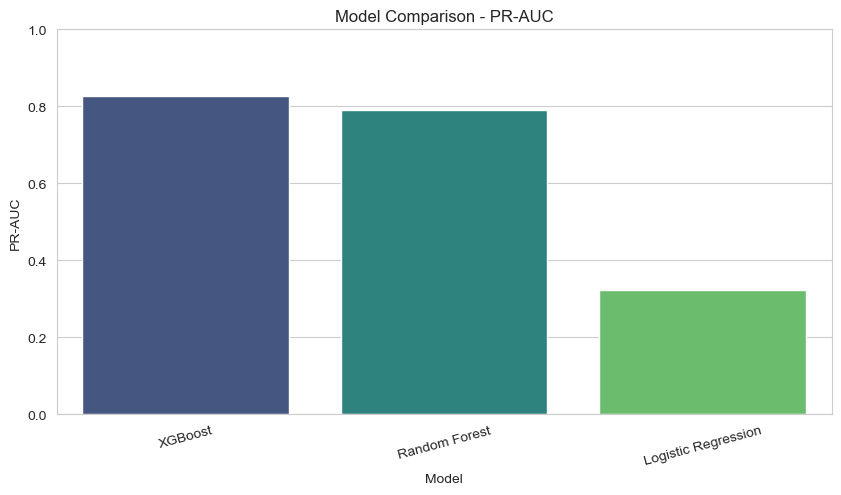

Selected Model: XGBoost


In [ ]:
# COMPARE ALL THREE MODELS 
models = {
    'Logistic Regression': v1_model,
    'Random Forest': v2_model,
    'XGBoost': v3_model
}

comparison_results = []

for model_name, model in models.items():

    probabilities = model.predict_proba(X_val)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    comparison_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_val, predictions),
        'Precision': precision_score(y_val, predictions, zero_division=0),
        'Recall': recall_score(y_val, predictions, zero_division=0),
        'F1 Score': f1_score(y_val, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(y_val, probabilities),
        'PR-AUC': average_precision_score(y_val, probabilities)
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by='PR-AUC',
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

# Visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison_df,
    x='Model',
    y='PR-AUC',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title("Model Comparison - PR-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

# Select best model using validation PR-AUC
best_model_name = comparison_df.iloc[0]['Model']
best_model = models[best_model_name]

print("Selected Model:", best_model_name)

Selected Model: XGBoost
Optimized Threshold: 0.9910709857940674
Validation Precision: 0.9523809523809523
Validation Recall: 0.759493670886076
Validation F1 Score: 0.8450704224858461


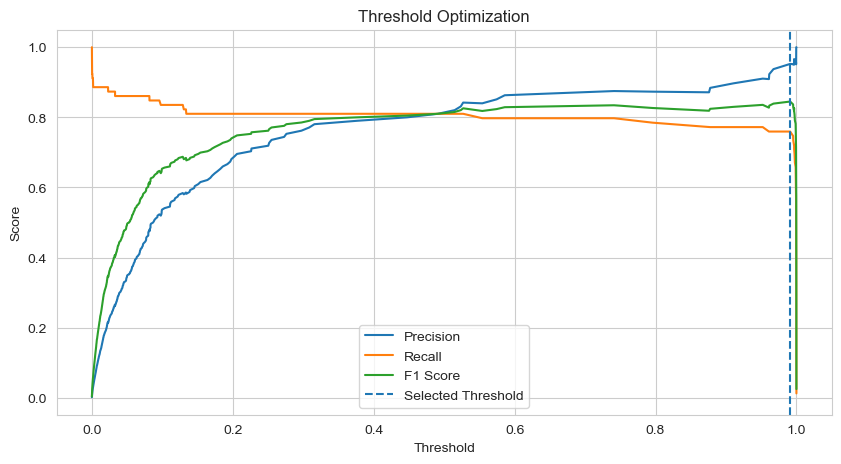

In [ ]:
# Threshold optimization 
best_val_probabilities = best_model.predict_proba(X_val)[:, 1]

precision_values, recall_values, thresholds = precision_recall_curve(
    y_val,
    best_val_probabilities
)

f1_values = (
    2 * precision_values[:-1] * recall_values[:-1] /
    (precision_values[:-1] + recall_values[:-1] + 1e-10)
)

best_threshold_index = np.argmax(f1_values)
best_threshold = float(thresholds[best_threshold_index])

print("Selected Model:", best_model_name)
print("Optimized Threshold:", best_threshold)
print("Validation Precision:", precision_values[best_threshold_index])
print("Validation Recall:", recall_values[best_threshold_index])
print("Validation F1 Score:", f1_values[best_threshold_index])

# Plot precision and recall against threshold
plt.figure(figsize=(10, 5))

plt.plot(thresholds, precision_values[:-1], label='Precision')
plt.plot(thresholds, recall_values[:-1], label='Recall')
plt.plot(thresholds, f1_values, label='F1 Score')

plt.axvline(
    best_threshold,
    linestyle='--',
    label='Selected Threshold'
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold Optimization")
plt.legend()
plt.show()

In [ ]:
# final training model 
# Retrain selected model on complete training dataset
best_model.fit(X_train, y_train)

# Final test probabilities
test_probabilities = best_model.predict_proba(X_test)[:, 1]

# Predictions using optimized threshold
test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("FINAL MODEL:", best_model_name)
print("=" * 50)

print("Accuracy:",
      accuracy_score(y_test, test_predictions))

print("Precision:",
      precision_score(y_test, test_predictions, zero_division=0))

print("Recall:",
      recall_score(y_test, test_predictions, zero_division=0))

print("F1 Score:",
      f1_score(y_test, test_predictions, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, test_probabilities))

print("PR-AUC:",
      average_precision_score(y_test, test_probabilities))

print("\nFINAL CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=['Genuine', 'Fraud'],
        zero_division=0
    )
)

FINAL MODEL: XGBoost
Accuracy: 0.9994733330992591
Precision: 0.925
Recall: 0.7551020408163265
F1 Score: 0.8314606741573034
ROC-AUC: 0.9789668223789234
PR-AUC: 0.8664519702154966

FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00     56864
       Fraud       0.93      0.76      0.83        98

    accuracy                           1.00     56962
   macro avg       0.96      0.88      0.92     56962
weighted avg       1.00      1.00      1.00     56962



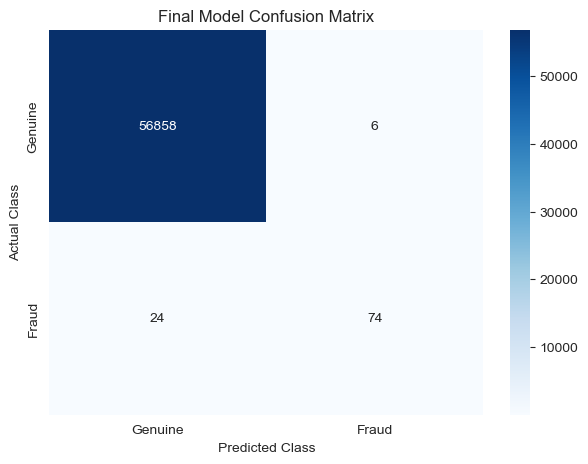

True Negatives: 56858
False Positives: 6
False Negatives: 24
True Positives: 74

Frauds Correctly Detected: 74
Frauds Missed: 24
False Fraud Alerts: 6


In [ ]:
# CONFUSION MATRIX 
cm = confusion_matrix(y_test, test_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Genuine', 'Fraud'],
    yticklabels=['Genuine', 'Fraud']
)

plt.title("Final Model Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nFrauds Correctly Detected:", tp)
print("Frauds Missed:", fn)
print("False Fraud Alerts:", fp)


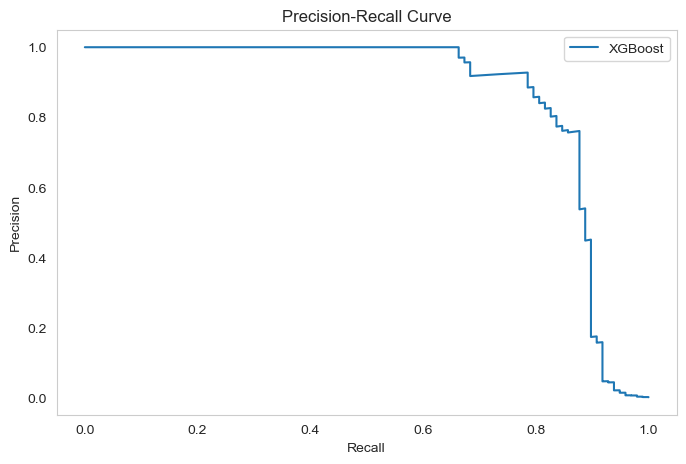

Average Precision: 0.8664519702154966


In [ ]:
# PRECISION-RECALL CURVE 
precision_curve, recall_curve, _ = precision_recall_curve(
    y_test,
    test_probabilities
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall_curve,
    precision_curve,
    label=f'{best_model_name}'
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid()
plt.show()

print(
    "Average Precision:",
    average_precision_score(y_test, test_probabilities)
)

,Feature,Importance
14,V14,0.401684
10,V10,0.073208
4,V4,0.066287
12,V12,0.055547
20,V20,0.034745
29,Amount,0.029808
8,V8,0.028150
26,V26,0.020814
3,V3,0.020063
7,V7,0.019390


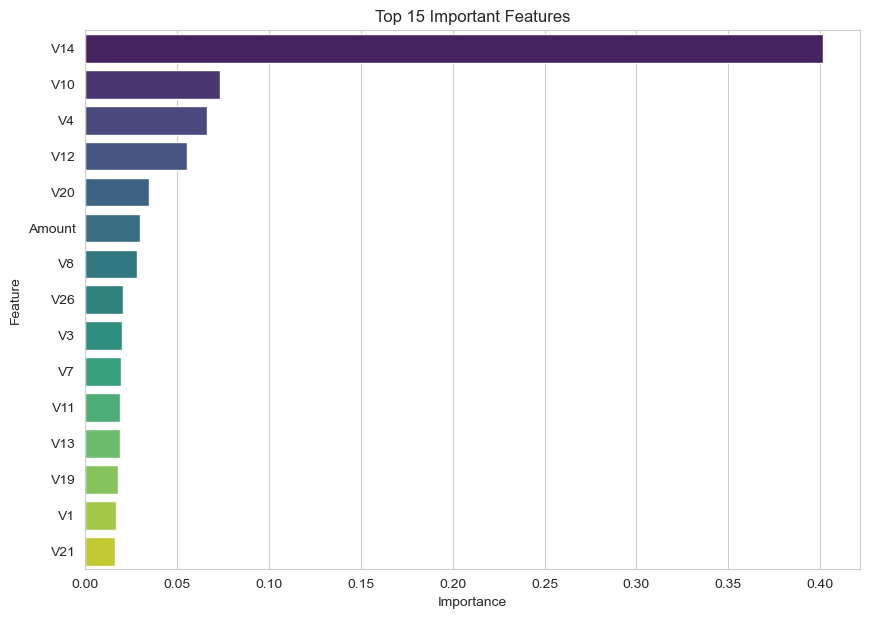

In [ ]:
# FEATURE IMPORTANCE
classifier = best_model.named_steps['classifier']

if hasattr(classifier, 'feature_importances_'):

    importance_df = pd.DataFrame({
        'Feature': X_train.columns,
        'Importance': classifier.feature_importances_
    })

    importance_df = importance_df.sort_values(
        by='Importance',
        ascending=False
    )

    display(importance_df.head(15))

    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=importance_df.head(15),
        x='Importance',
        y='Feature',
        hue='Feature',
        palette='viridis',
        legend=False
    )

    plt.title("Top 15 Important Features")
    plt.show()

else:
    print("Feature importance is not directly available for this model.")

Model successfully saved!
File: models/credit_fraud_model.pkl
Selected Algorithm: XGBoost
Selected Threshold: 0.9910709857940674


In [4]:
print("best_model:", "best_model" in globals())
print("best_model_name:", "best_model_name" in globals())
print("best_threshold:", "best_threshold" in globals())

best_model: False
best_model_name: False
best_threshold: False
